In [55]:
from SyntheticData.simulate_data import simulate_competing_risks

import pandas as pd
import numpy as np

import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import KFold
import random
import os
from sksurv.metrics import integrated_brier_score
from pycox.evaluation import EvalSurv
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
from sksurv.nonparametric import kaplan_meier_estimator
from typing import Optional, Tuple
from pathlib import Path


# Data Used

In [56]:
df_synthetic, true_beta_event1, true_beta_event2 = simulate_competing_risks(n_samples=6000, seed=42,baseline_hazard_event1=0.01, baseline_hazard_event2=0.05,censoring_rate=0.01)

df_synthetic.head()

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,time,event,true_lp_event1,true_lp_event2
0,0.304717,-1.039984,0.750451,0.940565,-1.951035,-1.302180,1.0,1.0,0.0,1.0,1.0,0.0,15.084821,1,1.903896,-0.961819
1,0.127840,-0.316243,-0.016801,-0.853044,0.879398,0.777792,1.0,1.0,0.0,1.0,0.0,0.0,10.759874,2,0.970361,-0.329685
2,0.066031,1.127241,0.467509,-0.859292,0.368751,-0.958883,0.0,1.0,1.0,1.0,0.0,0.0,14.434709,2,-1.886839,2.073734
3,0.878450,-0.049926,-0.184862,-0.680930,1.222541,-0.154529,1.0,1.0,0.0,0.0,1.0,1.0,1.045714,2,2.396907,1.249025
4,-0.428328,-0.352134,0.532309,0.365444,0.412733,0.430821,0.0,1.0,0.0,1.0,0.0,1.0,128.513629,2,-2.304155,-1.329695


In [57]:
print(df_synthetic['event'].value_counts())

event
2    3598
1    1500
0     902
Name: count, dtype: int64


In [58]:
print(df_synthetic['true_lp_event1'].var(), df_synthetic['true_lp_event2'].var())

4.638129255958264 3.423580494411822


# Profiler

In [59]:
import psutil
import time
import threading
import pandas as pd
import matplotlib.pyplot as plt

def monitor_resources(interval, stats, stop_event):
    process = psutil.Process()
    while not stop_event.is_set():
        cpu = process.cpu_percent()
        mem = process.memory_info().rss / (1024 * 1024)  # in MB
        timestamp = time.time()
        stats.append({'time': timestamp, 'cpu': cpu, 'memory': mem})
        time.sleep(interval)

def profile_function(func, *args, interval=0.5, **kwargs):
    stats = []
    stop_event = threading.Event()

    monitor_thread = threading.Thread(target=monitor_resources, args=(interval, stats, stop_event))
    
    start_time = time.time()
    monitor_thread.start()

    result = func(*args, **kwargs)

    stop_event.set()
    monitor_thread.join()
    end_time = time.time()

    duration = end_time - start_time
    print(f"Function took {duration:.2f} seconds")

    return result, pd.DataFrame(stats), duration


# Model

In [60]:
class FeatureNet(nn.Module):
    """
    Standalone subnetwork for a single covariate.
    Outputs a vector of size output_dim (one per cause).
    """
    def __init__(self, hidden_dim: int, num_hidden_layers: int, dropout: float, output_dim: int):
        super().__init__()
        layers = []
        in_dim = 1
        
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.Tanh())
            layers.append(nn.Dropout(dropout))
            in_dim = hidden_dim
            
        # Final layer outputs output_dim values (log‑risk contributions for each cause)
        layers.append(nn.Linear(hidden_dim, output_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)   # shape: [batch_size, output_dim]


class CRISPNAMBase(nn.Module):
    """
    Base CRISPNAM network for the full-risk competing risks baseline.
    
    Structure:
      input -> [FeatureNet_1, ..., FeatureNet_p] -> Additive Aggregation -> output head
    """
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int = 32,
        num_hidden_layers: int = 5,
        dropout: float = 0.2,
        output_dim: int = 1,   # Base model predicts 1 target cause at a time
    ):
        super().__init__()

        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim

        # Instantiate a standalone FeatureNet for each input dimension
        self.feature_nets = nn.ModuleList([
            FeatureNet(hidden_dim, num_hidden_layers, dropout, output_dim) for _ in range(input_dim)
        ])
        
        # Global bias term for the additive model
        self.bias = nn.Parameter(torch.zeros(1))

        self._reset_parameters()

    def _reset_parameters(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor, return_embedding: bool = False) -> torch.Tensor | Tuple[torch.Tensor, torch.Tensor]:
        """
        Integrated Model Flow
        """
        feature_outputs = []
        
        # Pass each individual feature through its dedicated FeatureNet
        for i in range(self.input_dim):
            # Extract single feature, reshape to [batch_size, 1]
            feat = x[:, i].unsqueeze(1)
            out = self.feature_nets[i](feat) 
            feature_outputs.append(out)
            
        # Stack into shape: [batch_size, input_dim, 1]
        stacked_outputs = torch.stack(feature_outputs, dim=1)
        
        # Additive aggregation: Sum across the feature dimension
        # Shape becomes [batch_size, 1]
        risk_score = stacked_outputs.sum(dim=1) + self.bias
        
        if return_embedding:
            # Return the final score and the matrix of individual feature contributions
            return risk_score, stacked_outputs
        return risk_score
    
    def compute_baseline_subdistribution_hazards(self, train_loader,cause= 1, device="cuda"):
        """
        Computes the baseline subdistribution hazards for Cause 1 
        using Breslow-type estimator logic for the Fine-Gray model.
        """
        self.eval()
        all_times = []
        all_events = []
        all_risks = []
        
        with torch.no_grad():
            for batch_x, batch_t, batch_e in train_loader:
                batch_x = batch_x.to(device)
                risk_scores = self.forward(batch_x).cpu().numpy().flatten()
                
                all_times.extend(batch_t.numpy())
                all_events.extend(batch_e.numpy())
                all_risks.extend(np.exp(risk_scores)) # Convert log-risk to hazard ratio
                
        times = np.array(all_times)
        events = np.array(all_events)
        risks = np.array(all_risks)
        
        # Sort everything by time
        idx = np.argsort(times)
        times, events, risks = times[idx], events[idx], risks[idx]
        
        unique_times = np.unique(times)
        baseline_hazards = []
        
        for t in unique_times:
            
            risk_set_mask = (times >= t) | ((times < t) & (events != cause) & (events != 0))
            
            # Count failures for the specified cause at this exact time
            failures = np.sum((times == t) & (events == cause))
            sum_risk = np.sum(risks[risk_set_mask])
            
            if sum_risk > 0:
                baseline_hazards.append(failures / sum_risk)
            else:
                baseline_hazards.append(0.0)
                
        # Return unique time steps and the accumulated cumulative baseline hazard
        return unique_times, np.cumsum(baseline_hazards)

    def predict_survival(self, x: torch.Tensor, times: np.ndarray, baseline_times=None, baseline_cum_hazard=None) -> torch.Tensor:
        """
        Predicts mathematically valid survival probabilities at specified time points.
        """
        log_risk = self.forward(x) 
        hazard_ratio = torch.exp(log_risk)
        
        if baseline_times is None or baseline_cum_hazard is None:
            grid_tensor = torch.tensor(times, dtype=torch.float32, device=x.device)
            cif = 1.0 - torch.exp(-hazard_ratio @ grid_tensor.unsqueeze(0) * 0.01)
        else:
            interp_hazard = np.interp(times, baseline_times, baseline_cum_hazard)
            interp_hazard_tensor = torch.tensor(interp_hazard, dtype=torch.float32, device=x.device)
            cif = 1.0 - torch.exp(-hazard_ratio @ interp_hazard_tensor.unsqueeze(0))
        
        survival_probs = 1.0 - cif
        return torch.clamp(survival_probs, 0.0, 1.0)

In [61]:
# model = CRISPNAMBase(input_dim=12,hidden_dim=32,num_hidden_layers=5,dropout=0.2,output_dim=2)

In [62]:



# -----------------------------
# 1) Full-cohort risk set helper
# -----------------------------
class RisksetSampling:
    """
    Full cohort risk set construction for Fine-Gray style competing risks.

    Base definition used here for cause k:
        j is in the risk set for event i if
        T_j >= T_i  OR  (T_j < T_i and D_j != k)

    This keeps subjects with competing events in the subdistribution risk set.
    """

    def __init__(self, cause: int = 1):
        self.cause = cause

    def build_mask(self, times: torch.Tensor, events: torch.Tensor) -> torch.Tensor:
        """
        Returns:
            risk_mask: [n, n] boolean tensor
                       risk_mask[i, j] = True if j is in risk set for i
        """
        times = times.view(-1)
        events = events.view(-1)

        t_i = times.unsqueeze(1)  # [n, 1]
        t_j = times.unsqueeze(0)  # [1, n]
        e_j = events.unsqueeze(0) # [1, n]

        # Full Fine-Gray subdistribution risk set
        risk_mask = (t_j >= t_i) | ((t_j < t_i) & (e_j != self.cause) & (e_j != 0))
        return risk_mask

    def event_indices(self, events: torch.Tensor) -> torch.Tensor:
        return torch.where(events.view(-1) == self.cause)[0]

In [63]:
class FineGrayLoss(nn.Module):
    """
    Fine‑Gray negative log‑partial likelihood for a specific cause.
    Uses the full risk set (no sampling, no IPCW, no class weights).
    """
    def __init__(self, cause: int = 1):
        super().__init__()
        self.cause = cause

    def forward(self, risk_scores: torch.Tensor, times: torch.Tensor, events: torch.Tensor) -> torch.Tensor:
        """
        Args:
            risk_scores: [N] or [N,1] predicted log‑hazard ratios for the cause.
            times:       [N] observed event times.
            events:      [N] event indicators (0=censored, 1..K=causes).
        Returns:
            scalar loss (negative average partial likelihood) for self.cause.
        """
        # Ensure risk_scores is 1D
        if risk_scores.dim() == 2 and risk_scores.shape[1] == 1:
            risk_scores = risk_scores.squeeze(1)
        elif risk_scores.dim() != 1:
            raise ValueError(f"Expected 1D or [N,1] risk_scores, got {risk_scores.shape}")

        # Indices of subjects who experienced the target cause
        event_idx = torch.where(events == self.cause)[0]
        if len(event_idx) == 0:
            return torch.tensor(0.0, device=risk_scores.device, requires_grad=True)

        # Build risk set mask for the target cause
        sampler = RisksetSampling(cause=self.cause)
        risk_mask = sampler.build_mask(times, events)   # [N, N]

        # Extract rows for events of this cause
        risk_mask_events = risk_mask[event_idx]         # [n_events, N]

        loss_k = 0.0
        for i, idx in enumerate(event_idx):
            mask = risk_mask_events[i]
            denom = torch.logsumexp(risk_scores[mask], dim=0)
            loss_k += risk_scores[idx] - denom

        return -loss_k / len(event_idx)

In [64]:
class BatchFineGrayLossSingle(nn.Module):
    def __init__(self, cause=1):
        super().__init__()
        self.cause = cause

    def forward(self, risk_scores, times, events):
        # risk_scores: [batch_size] (scalar per subject)
        # times: [batch_size]
        # events: [batch_size]
        batch_size = risk_scores.shape[0]
        event_idx = torch.where(events == self.cause)[0]
        if len(event_idx) == 0:
            return torch.tensor(0.0, device=risk_scores.device, requires_grad=True)

        t_i = times[event_idx].unsqueeze(1)  # [n_events, 1]
        t_j = times.unsqueeze(0)             # [1, batch_size]
        e_j = events.unsqueeze(0)            # [1, batch_size]

        # Risk set mask for batch (approximation!)
        risk_mask = (t_j >= t_i) | (e_j != self.cause)

        loss = 0.0
        for idx, i in enumerate(event_idx):
            mask = risk_mask[idx]
            if mask.any():
                denom = torch.logsumexp(risk_scores[mask], dim=0)
                loss += risk_scores[i] - denom
        return -loss / len(event_idx)

In [65]:

# -----------------------------
# 3) Early stopping utility
# -----------------------------
class EarlyStopping:
    def __init__(self, patience: int = 10, min_delta: float = 0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.best_state = None
        self.should_stop = False

    def step(self, val_loss: float, model: nn.Module):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True


In [66]:
def train_model_minibatch(
    model,
    optimizer,
    train_loader,
    val_loader,
    criterion,
    num_epochs=100,
    patience=10,
    device="cuda"
):
    model = model.to(device)
    stopper = EarlyStopping(patience=patience)
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(num_epochs):
        # ---- Training ----
        model.train()
        train_loss = 0.0
        num_batches = 0
        for batch_x, batch_t, batch_e in train_loader:
            batch_x, batch_t, batch_e = batch_x.to(device), batch_t.to(device), batch_e.to(device)
            optimizer.zero_grad()
            preds = model(batch_x).squeeze(-1)   # [batch_size]
            loss = criterion(preds, batch_t, batch_e)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            num_batches += 1
        avg_train_loss = train_loss / num_batches

        # ---- Validation ----
        model.eval()
        val_loss = 0.0
        num_val_batches = 0
        with torch.no_grad():
            for batch_x, batch_t, batch_e in val_loader:
                batch_x, batch_t, batch_e = batch_x.to(device), batch_t.to(device), batch_e.to(device)
                preds = model(batch_x).squeeze(-1)
                loss = criterion(preds, batch_t, batch_e)
                val_loss += loss.item()
                num_val_batches += 1
        avg_val_loss = val_loss / num_val_batches

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        print(f"Epoch {epoch+1:03d} | train_loss={avg_train_loss:.4f} | val_loss={avg_val_loss:.4f}")

        stopper.step(avg_val_loss, model)
        if stopper.should_stop:
            break

    if stopper.best_state is not None:
        model.load_state_dict(stopper.best_state)
    return model, history

In [67]:
def _collect_full_cohort(loader, device):
    xs, ts, es = [], [], []
    for batch in loader:
        x, t, e = batch[:3]
        xs.append(x.to(device))
        ts.append(t.to(device))
        es.append(e.to(device))
    return torch.cat(xs, dim=0), torch.cat(ts, dim=0), torch.cat(es, dim=0)

def train_model_full_cohort(
    model,
    optimizer,
    train_loader,
    val_loader,
    criterion,            # the FineGrayLoss defined above
    num_epochs: int = 100,
    patience: int = 10,
    device: str = "cuda" if torch.cuda.is_available() else "cpu",
):
    model = model.to(device)
    stopper = EarlyStopping(patience=patience)

    # Collect full training data once (no batching inside loop)
    train_x, train_t, train_e = _collect_full_cohort(train_loader, device)
    # Collect full validation data once (for loss computation)
    val_x, val_t, val_e = _collect_full_cohort(val_loader, device)

    history = {"train_loss": [], "val_loss": []}

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()
        preds = model(train_x)                     # [N_train, K]
        loss = criterion(preds, train_t, train_e)
        loss.backward()
        optimizer.step()
        train_loss_val = loss.item()

        # Validation
        model.eval()
        with torch.no_grad():
            val_preds = model(val_x)               # [N_val, K]
            val_loss = criterion(val_preds, val_t, val_e)
        val_loss_val = val_loss.item()

        history["train_loss"].append(train_loss_val)
        history["val_loss"].append(val_loss_val)

        print(f"Epoch {epoch+1:03d}/{num_epochs} | train_loss={train_loss_val:.6f} | val_loss={val_loss_val:.6f}")

        stopper.step(val_loss_val, model)
        if stopper.should_stop:
            print(f"Early stopping at epoch {epoch+1}.")
            break

    if stopper.best_state is not None:
        model.load_state_dict(stopper.best_state)

    return model, history

In [68]:
def train_model_5fold_full_cohort(
    build_model_fn,
    X,
    times,
    events,
    batch_size: int = 256,   # only used for DataLoader, but training will collect all
    num_epochs: int = 100,
    patience: int = 10,
    k_folds: int = 5,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,   # L2 regularization via Adam
    cause: int = 1,               
    seed: int = 42,
    device: str = "cuda" if torch.cuda.is_available() else "cpu",
):
    X_np = X.values if hasattr(X, 'values') else np.array(X)
    times_np = times.values if hasattr(times, 'values') else np.array(times)
    events_np = events.values if hasattr(events, 'values') else np.array(events)

    X_tensor = torch.tensor(X_np, dtype=torch.float32)
    times_tensor = torch.tensor(times_np, dtype=torch.float32)
    events_tensor = torch.tensor(events_np, dtype=torch.long)

    kf = KFold(n_splits=k_folds, shuffle=True, random_state=seed)

    criterion = FineGrayLoss(cause=cause)   # base loss, no gamma

    fold_histories = []
    fold_models = []
    fold_ibs_scores = []
    fold_cindex_scores = []
    fold_resource_logs = []
    fold_training_durations = []
    all_test_predictions = []
    all_test_indices = []
    all_true_times = []
    all_true_events = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_tensor), start=1):
        print(f"\n===== Fold {fold}/{k_folds} =====")

        X_train, X_val = X_tensor[train_idx], X_tensor[val_idx]
        t_train, t_val = times_tensor[train_idx], times_tensor[val_idx]
        e_train, e_val = events_tensor[train_idx], events_tensor[val_idx]

        train_ds = TensorDataset(X_train, t_train, e_train)
        val_ds = TensorDataset(X_val, t_val, e_val)

        # DataLoaders still used for _collect_full_cohort
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False)
        val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

        model = build_model_fn().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)


        def train_model() :
            return train_model_full_cohort(
                model=model,
                optimizer=optimizer,
                train_loader=train_loader,
                val_loader=val_loader,
                criterion=criterion,
                num_epochs=num_epochs,
                patience=patience,
                device=device,
            )
        (model, history),training_resource_log, training_duration = profile_function(train_model)

        # ---- Evaluation (same as before) ----
        model.eval()
        time_grid = np.percentile(times_np[val_idx], np.linspace(5, 99, 100))
        with torch.no_grad():
            base_times, cum_hazard = model.compute_baseline_subdistribution_hazards(train_loader, cause=cause, device=device)
            val_preds = model.predict_survival(X_val.to(device), times=time_grid,
                                               baseline_times=base_times, baseline_cum_hazard=cum_hazard)
            val_preds = val_preds.cpu().numpy()

            all_test_predictions.append(val_preds)
            all_test_indices.append(val_idx)
            all_true_times.append(times_np[val_idx])
            all_true_events.append(events_np[val_idx])

            # Pycox evaluation
            if val_preds.shape[0] != len(time_grid):
                val_preds_df = pd.DataFrame(val_preds.T, index=time_grid)
            else:
                val_preds_df = pd.DataFrame(val_preds, index=time_grid)

            durations_val = times_np[val_idx]
            events_val = (events_np[val_idx] == cause).astype(int)
            ev = EvalSurv(surv=val_preds_df, durations=durations_val, events=events_val, censor_surv=None, censor_durations=None)

            # Censoring estimate from training set (for IPCW in Brier score)
            censoring_mask_train = (events_np[train_idx] == 0)
            time_cens, prob_cens = kaplan_meier_estimator(censoring_mask_train, times_np[train_idx])
            prob_cens = np.clip(prob_cens, 1e-8, 1.0)
            if time_cens[0] > 0:
                time_cens = np.insert(time_cens, 0, 0.0)
                prob_cens = np.insert(prob_cens, 0, 1.0)
            prob_cens_2d = np.tile(prob_cens[:, np.newaxis], (1, len(val_idx)))
            censor_surv_2d = pd.DataFrame(prob_cens_2d, index=time_cens, columns=val_preds_df.columns)
            ev.add_censor_est(censor_surv_2d)

            score_ibs = ev.integrated_brier_score(time_grid)
            score_c_idx = ev.concordance_td('antolini')
            fold_ibs_scores.append(score_ibs)
            fold_cindex_scores.append(score_c_idx)
            print(f"Fold {fold} | IBS: {score_ibs:.4f} | C-Index: {score_c_idx:.4f}")
            print(f"Fold {fold} | Training Duration: {training_duration:.2f} seconds")

        fold_models.append(model)
        fold_histories.append(history)
        fold_resource_logs.append(training_resource_log)
        fold_training_durations.append(training_duration)

    print(f"\n===== CV Complete =====")
    print(f"Mean C-index: {np.mean(fold_cindex_scores):.4f} +/- {np.std(fold_cindex_scores):.4f}")
    print(f"Mean IBS: {np.mean(fold_ibs_scores):.4f} +/- {np.std(fold_ibs_scores):.4f}")

    return fold_models, fold_histories, fold_ibs_scores, fold_cindex_scores, all_test_predictions, all_test_indices, all_true_times, all_true_events

In [69]:
from dataclasses import dataclass
import numpy as np
import pandas as pd

@dataclass
class BrierScoreResult:
    time_grid: np.ndarray
    scores: np.ndarray

    @property
    def mean(self) -> float:
        """Mean Brier score across the time grid for this fold."""
        return float(np.mean(self.scores))

    @property
    def std(self) -> float:
        """Standard deviation of Brier scores across time for this fold."""
        return float(np.std(self.scores))

    def to_dataframe() -> pd.DataFrame:
        """Helper to convert to DataFrame whenever you need to save to CSV."""
        return pd.DataFrame({
            'time': self.time_grid,
            'brier_score': self.scores
        })

In [70]:
def train_model_5fold_full_cohort_minibatch_training(
    build_model_fn,
    X,
    times,
    events,
    batch_size: int = 256,   # only used for DataLoader, but training will collect all
    num_epochs: int = 100,
    patience: int = 10,
    k_folds: int = 5,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,   # L2 regularization via Adam
    cause: int = 1,               
    seed: int = 42,
    device: str = "cuda" if torch.cuda.is_available() else "cpu",
):
    X_np = X.values if hasattr(X, 'values') else np.array(X)
    times_np = times.values if hasattr(times, 'values') else np.array(times)
    events_np = events.values if hasattr(events, 'values') else np.array(events)

    X_tensor = torch.tensor(X_np, dtype=torch.float32)
    times_tensor = torch.tensor(times_np, dtype=torch.float32)
    events_tensor = torch.tensor(events_np, dtype=torch.long)

    kf = KFold(n_splits=k_folds, shuffle=True, random_state=seed)

    criterion = BatchFineGrayLossSingle(cause=cause)

    fold_histories = []
    fold_models = []
    fold_ibs_scores = []
    fold_cindex_scores = []
    fold_brier_scores = []
    fold_resource_logs = []
    fold_training_durations = []
    all_test_predictions = []
    all_test_indices = []
    all_true_times = []
    all_true_events = []


    for fold, (train_idx, val_idx) in enumerate(kf.split(X_tensor), start=1):
        print(f"\n===== Fold {fold}/{k_folds} =====")

        X_train, X_val = X_tensor[train_idx], X_tensor[val_idx]
        t_train, t_val = times_tensor[train_idx], times_tensor[val_idx]
        e_train, e_val = events_tensor[train_idx], events_tensor[val_idx]

        train_ds = TensorDataset(X_train, t_train, e_train)
        val_ds = TensorDataset(X_val, t_val, e_val)

        # DataLoaders still used for _collect_full_cohort
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False)
        val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

        model = build_model_fn().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

        
        def train_model() :
            return train_model_minibatch(
                model=model,
                optimizer=optimizer,
                train_loader=train_loader,
                val_loader=val_loader,
                criterion=criterion,
                num_epochs=num_epochs,
                patience=patience,
                device=device,
            )
        
        (model, history), resource_log, training_duration = profile_function(train_model)

        # ---- Evaluation (same as before) ----
        model.eval()
        time_grid = np.percentile(times_np[val_idx], np.linspace(5, 99, 100))
        with torch.no_grad():
            base_times, cum_hazard = model.compute_baseline_subdistribution_hazards(train_loader, cause=cause, device=device)
            val_preds = model.predict_survival(X_val.to(device), times=time_grid,
                                               baseline_times=base_times, baseline_cum_hazard=cum_hazard)
            val_preds = val_preds.cpu().numpy()

            all_test_predictions.append(val_preds)
            all_test_indices.append(val_idx)
            all_true_times.append(times_np[val_idx])
            all_true_events.append(events_np[val_idx])

            # Pycox evaluation
            if val_preds.shape[0] != len(time_grid):
                val_preds_df = pd.DataFrame(val_preds.T, index=time_grid)
            else:
                val_preds_df = pd.DataFrame(val_preds, index=time_grid)

            durations_val = times_np[val_idx]
            events_val = (events_np[val_idx] == cause).astype(int)
            ev = EvalSurv(surv=val_preds_df, durations=durations_val, events=events_val, censor_surv=None, censor_durations=None)

            # Censoring estimate from training set (for IPCW in Brier score)
            censoring_mask_train = (events_np[train_idx] == 0)
            time_cens, prob_cens = kaplan_meier_estimator(censoring_mask_train, times_np[train_idx])
            prob_cens = np.clip(prob_cens, 1e-8, 1.0)
            if time_cens[0] > 0:
                time_cens = np.insert(time_cens, 0, 0.0)
                prob_cens = np.insert(prob_cens, 0, 1.0)
            prob_cens_2d = np.tile(prob_cens[:, np.newaxis], (1, len(val_idx)))
            censor_surv_2d = pd.DataFrame(prob_cens_2d, index=time_cens, columns=val_preds_df.columns)
            ev.add_censor_est(censor_surv_2d)

            score_ibs = ev.integrated_brier_score(time_grid)
            score_c_idx = ev.concordance_td('antolini')

            
            score_brier_series = ev.brier_score(time_grid)

            brier_obj = BrierScoreResult(time_grid=time_grid, scores=score_brier_series.values)
            


            fold_ibs_scores.append(score_ibs)
            fold_cindex_scores.append(score_c_idx)
            fold_brier_scores.append(brier_obj)
            print(f"Fold {fold} | IBS: {score_ibs:.4f} | C-Index: {score_c_idx:.4f}")
            print(f"Fold {fold} | Mean Brier Score: {brier_obj.mean:.4f} | Std Brier Score: {brier_obj.std:.4f}")
            print(f"Fold {fold} | Training Duration: {training_duration:.2f} seconds")

        fold_models.append(model)
        fold_histories.append(history)
        fold_resource_logs.append(resource_log)
        fold_training_durations.append(training_duration)


    fold_brier_means = [brier.mean for brier in fold_brier_scores]

    print(f"\n===== CV Complete =====")
    print(f"Mean C-index:    {np.mean(fold_cindex_scores):.4f} +/- {np.std(fold_cindex_scores):.4f}")
    print(f"Mean IBS:        {np.mean(fold_ibs_scores):.4f} +/- {np.std(fold_ibs_scores):.4f}")
    print(f"Mean Brier Score: {np.mean(fold_brier_means):.4f} +/- {np.std(fold_brier_means):.4f}")

    return fold_models, fold_histories, fold_ibs_scores, fold_brier_scores, fold_cindex_scores, all_test_predictions, all_test_indices, all_true_times, all_true_events, fold_resource_logs, fold_training_durations

In [71]:


def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # if you are using multi-GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"


In [72]:

set_seed(42)
# Example model builder
def build_model():
    return CRISPNAMBase(
        input_dim=12,
        hidden_dim=32,
        num_hidden_layers=5,
        dropout=0.2,
        output_dim=1
    )

df = df_synthetic
model_cause = 1  # Specify the cause of interest for training



# models, histories, ibs_scores, brier_scores, cindex_scores, all_test_predictions, all_test_indices, all_true_times, all_true_events, fold_resource_logs, fold_training_durations = train_model_5fold_full_cohort(
#         build_model_fn=build_model,
#         X=df.drop(['time', 'event','true_lp_event1','true_lp_event2'], axis=1),
#         times=df['time'],
#         events=df['event'],
#         batch_size=1000,      # still used for DataLoader, but training collects all
#         num_epochs=400,
#         patience=20,
#         k_folds=5,
#         lr=1e-3,
#         weight_decay=1e-4,    # L2 regularization via Adam
#         cause=model_cause
# )



models, histories, ibs_scores, brier_scores, cindex_scores, all_test_predictions, all_test_indices, all_true_times, all_true_events, fold_resource_logs, fold_training_durations = train_model_5fold_full_cohort_minibatch_training(
        build_model_fn=build_model,
        X=df.drop(['time', 'event','true_lp_event1','true_lp_event2'], axis=1),
        times=df['time'],
        events=df['event'],
        batch_size=1000,      # still used for DataLoader, but training collects all
        num_epochs=400,
        patience=20,
        k_folds=5,
        lr=1e-3,
        weight_decay=1e-4,    # L2 regularization via Adam
        cause=model_cause
)


===== Fold 1/5 =====
Epoch 001 | train_loss=7.1140 | val_loss=5.4160
Epoch 002 | train_loss=6.4364 | val_loss=5.1447
Epoch 003 | train_loss=6.1967 | val_loss=5.1259
Epoch 004 | train_loss=6.1267 | val_loss=5.1558
Epoch 005 | train_loss=6.1671 | val_loss=5.1462
Epoch 006 | train_loss=6.0624 | val_loss=5.1219
Epoch 007 | train_loss=6.0651 | val_loss=5.1020
Epoch 008 | train_loss=6.0574 | val_loss=5.0945
Epoch 009 | train_loss=6.0188 | val_loss=5.0979
Epoch 010 | train_loss=6.0467 | val_loss=5.1040
Epoch 011 | train_loss=6.0302 | val_loss=5.1079
Epoch 012 | train_loss=6.0108 | val_loss=5.1132
Epoch 013 | train_loss=6.0203 | val_loss=5.1157
Epoch 014 | train_loss=5.9886 | val_loss=5.1100
Epoch 015 | train_loss=5.9877 | val_loss=5.0980
Epoch 016 | train_loss=5.9758 | val_loss=5.0949
Epoch 017 | train_loss=5.9839 | val_loss=5.0962
Epoch 018 | train_loss=5.9669 | val_loss=5.0982
Epoch 019 | train_loss=5.9485 | val_loss=5.0945
Epoch 020 | train_loss=5.9541 | val_loss=5.0964
Epoch 021 | train_

# Evaluation

In [73]:
output_dir = Path("../Results/FullRisk/Metrics")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = f"{output_dir}/CIndex_scores_cause_{model_cause}.csv"

# Create per-fold DataFrame
df_scores = pd.DataFrame({
    "Fold": [f"Fold_{i}" for i in range(len(cindex_scores))],
    "CIndex_Score": cindex_scores
})

# Calculate mean and standard deviation
mean_score = df_scores["CIndex_Score"].mean()
std_score = df_scores["CIndex_Score"].std()

# Append summary rows
summary_df = pd.DataFrame([
    {"Fold": "Mean", "CIndex_Score": mean_score},
    {"Fold": "Std", "CIndex_Score": std_score}
])

df_final = pd.concat([df_scores, summary_df], ignore_index=True)

df_final.to_csv(output_file, index=False)

print(f"CIndex scores successfully saved to: {output_file}")
print("\nPreview of saved CSV:")
df_final

CIndex scores successfully saved to: ..\Results\FullRisk\Metrics/CIndex_scores_cause_1.csv

Preview of saved CSV:


,Fold,CIndex_Score
0,Fold_0,0.854036
1,Fold_1,0.858462
2,Fold_2,0.853170
3,Fold_3,0.868403
4,Fold_4,0.850558
5,Mean,0.856926
6,Std,0.007019


In [74]:
output_dir = Path("../Results/FullRisk/Metrics")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = f"{output_dir}/IBS_scores_cause_{model_cause}.csv"

# Create per-fold DataFrame
df_scores = pd.DataFrame({
    "Fold": [f"Fold_{i}" for i in range(len(ibs_scores))],
    "IBS_Score": ibs_scores
})

# Calculate mean and standard deviation
mean_score = df_scores["IBS_Score"].mean()
std_score = df_scores["IBS_Score"].std()

# Append summary rows
summary_df = pd.DataFrame([
    {"Fold": "Mean", "IBS_Score": mean_score},
    {"Fold": "Std", "IBS_Score": std_score}
])

df_final = pd.concat([df_scores, summary_df], ignore_index=True)

df_final.to_csv(output_file, index=False)

print(f"IBS scores successfully saved to: {output_file}")
print("\nPreview of saved CSV:")
df_final

IBS scores successfully saved to: ..\Results\FullRisk\Metrics/IBS_scores_cause_1.csv

Preview of saved CSV:


,Fold,IBS_Score
0,Fold_0,0.209729
1,Fold_1,0.189766
2,Fold_2,0.200864
3,Fold_3,0.214071
4,Fold_4,0.214956
5,Mean,0.205877
6,Std,0.010596


In [75]:
output_dir = Path("../Results/FullRisk/Metrics")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = f"{output_dir}/Training_Durations_cause_{model_cause}.csv"

# Create per-fold DataFrame
df_scores = pd.DataFrame({
    "Fold": [f"Fold_{i}" for i in range(len(fold_training_durations))],
    "Training_Duration": fold_training_durations
})

# Calculate mean and standard deviation
mean_score = df_scores["Training_Duration"].mean()
std_score = df_scores["Training_Duration"].std()

# Append summary rows
summary_df = pd.DataFrame([
    {"Fold": "Mean", "Training_Duration": mean_score},
    {"Fold": "Std", "Training_Duration": std_score}
])

df_final = pd.concat([df_scores, summary_df], ignore_index=True)

df_final.to_csv(output_file, index=False)

print(f"Training durations successfully saved to: {output_file}")
print("\nPreview of saved CSV:")
df_final

Training durations successfully saved to: ..\Results\FullRisk\Metrics/Training_Durations_cause_1.csv

Preview of saved CSV:


,Fold,Training_Duration
0,Fold_0,46.886951
1,Fold_1,35.419230
2,Fold_2,78.897418
3,Fold_3,39.680660
4,Fold_4,42.008555
5,Mean,48.578563
6,Std,17.447065


In [76]:
metrics_dir = Path("../Results/FullRisk/Metrics")
raw_dir = metrics_dir / f"Brier_Raw_cause_{model_cause}"

metrics_dir.mkdir(parents=True, exist_ok=True)
raw_dir.mkdir(parents=True, exist_ok=True)


fold_summary_rows = [
    {
        "Fold": f"Fold_{i}",
        "Mean": brier_obj.mean,
        "Std": brier_obj.std
    }
    for i, brier_obj in enumerate(brier_scores)
]

df_fold_summary = pd.DataFrame(fold_summary_rows)

# Calculate cross-validation mean and std across fold means
overall_mean = df_fold_summary["Mean"].mean()
overall_std = df_fold_summary["Mean"].std()

summary_rows = pd.DataFrame([
    {"Fold": "Mean", "Mean": overall_mean, "Std": np.nan},
    {"Fold": "Std", "Mean": overall_std, "Std": np.nan}
])

df_brier_scores = pd.concat([df_fold_summary, summary_rows], ignore_index=True)
summary_file = metrics_dir / f"brier_scores_cause_{model_cause}.csv"
df_brier_scores.to_csv(summary_file, index=False)


print(f"Summary saved to: {summary_file.resolve()}\n")


for i, brier_obj in enumerate(brier_scores):
    df_brier_raw = pd.DataFrame({
        "time": brier_obj.time_grid,
        "brier_score": brier_obj.scores
    })
    raw_file = raw_dir / f"brier_raw_fold_{i}.csv"
    df_brier_raw.to_csv(raw_file, index=False)
    print(f"Raw trajectory for Fold {i} saved to: {raw_file.resolve()}")

df_brier_scores

Summary saved to: C:\Users\micha\OneDrive\Documents\#Msc Data Science\Research_2026\Code\Fine-Gray-CRISP-NAM-Survival-Analysis-Using-Risk-Set-Sampling\Results\FullRisk\Metrics\brier_scores_cause_1.csv

Raw trajectory for Fold 0 saved to: C:\Users\micha\OneDrive\Documents\#Msc Data Science\Research_2026\Code\Fine-Gray-CRISP-NAM-Survival-Analysis-Using-Risk-Set-Sampling\Results\FullRisk\Metrics\Brier_Raw_cause_1\brier_raw_fold_0.csv
Raw trajectory for Fold 1 saved to: C:\Users\micha\OneDrive\Documents\#Msc Data Science\Research_2026\Code\Fine-Gray-CRISP-NAM-Survival-Analysis-Using-Risk-Set-Sampling\Results\FullRisk\Metrics\Brier_Raw_cause_1\brier_raw_fold_1.csv
Raw trajectory for Fold 2 saved to: C:\Users\micha\OneDrive\Documents\#Msc Data Science\Research_2026\Code\Fine-Gray-CRISP-NAM-Survival-Analysis-Using-Risk-Set-Sampling\Results\FullRisk\Metrics\Brier_Raw_cause_1\brier_raw_fold_2.csv
Raw trajectory for Fold 3 saved to: C:\Users\micha\OneDrive\Documents\#Msc Data Science\Research_20

,Fold,Mean,Std
0,Fold_0,0.108787,0.060293
1,Fold_1,0.106417,0.055734
2,Fold_2,0.108781,0.058151
3,Fold_3,0.118370,0.058693
4,Fold_4,0.113451,0.064224
5,Mean,0.111161,NaN
6,Std,0.004770,NaN


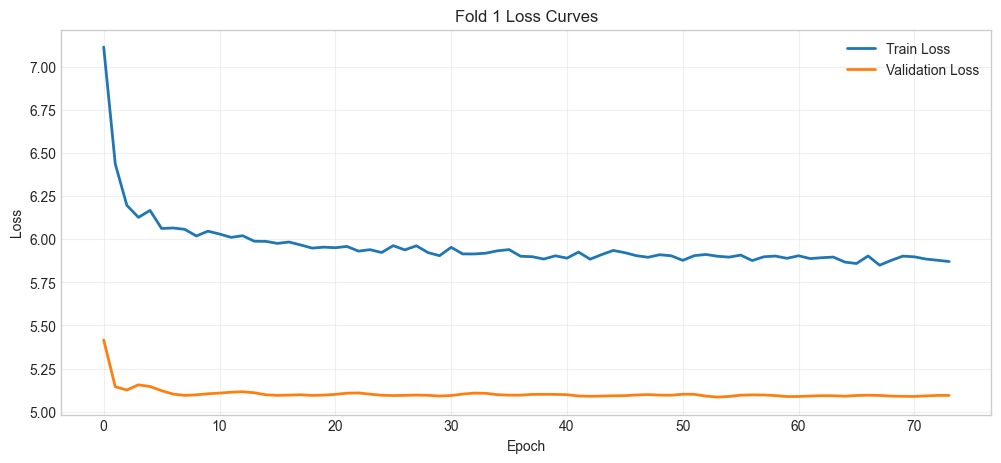

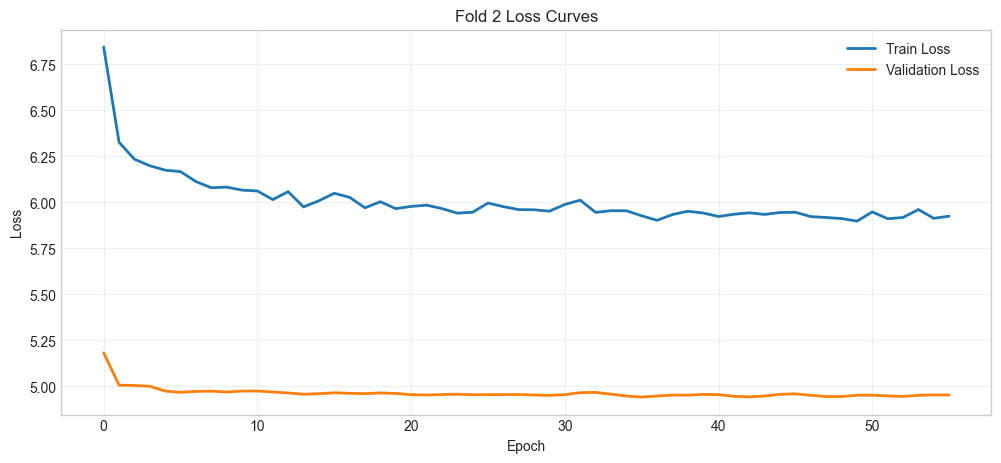

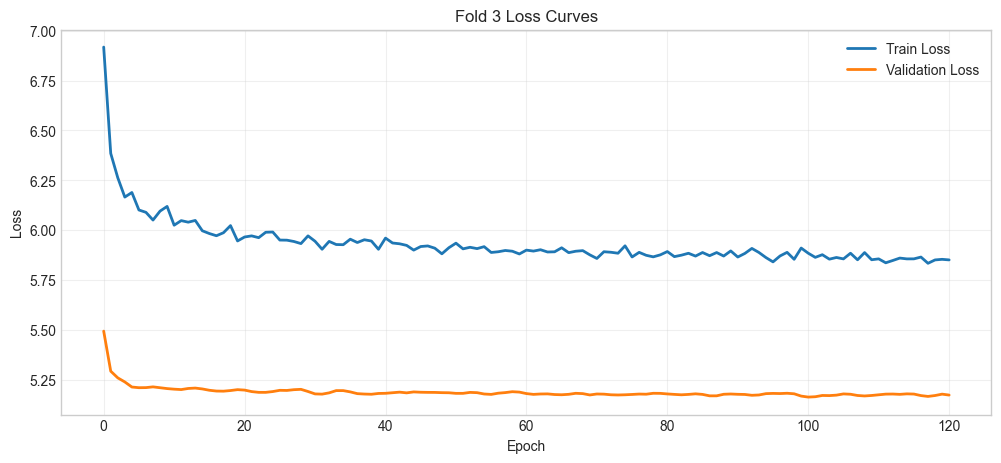

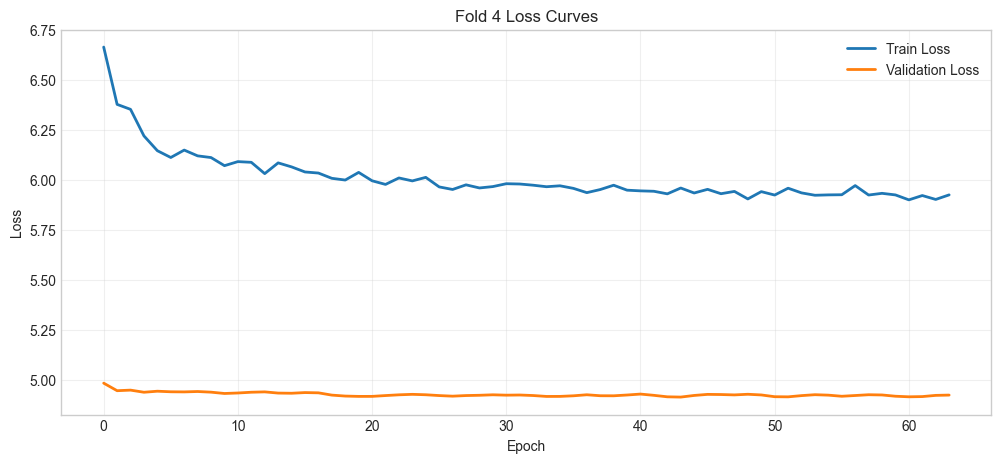

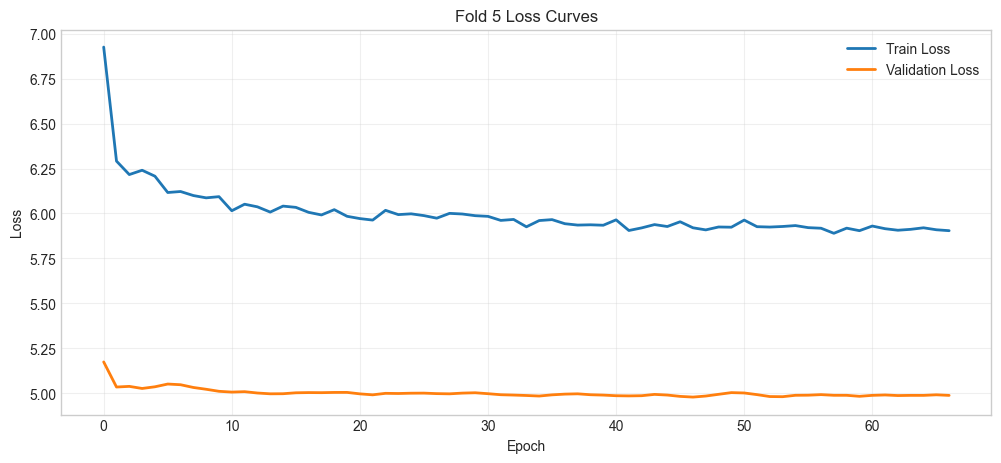

In [77]:

file_path = Path(f"../Results/FullRisk/Loss")
file_path.mkdir(parents=True, exist_ok=True)



for fold_idx, history in enumerate(histories, start=1):
    plt.figure(figsize=(12, 5))

    plt.plot(history["train_loss"], label="Train Loss", linewidth=2)
    plt.plot(history["val_loss"], label="Validation Loss", linewidth=2)

    plt.title(f"Fold {fold_idx} Loss Curves")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.savefig(f"{file_path}/fold_{fold_idx}_loss_cause_{model_cause}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pycox.evaluation import EvalSurv
from sksurv.nonparametric import kaplan_meier_estimator
from scipy.stats import spearmanr, pearsonr

def evaluate_and_compare_truth(
    all_test_predictions,
    all_test_indices,
    all_true_times,
    all_true_events,
    true_lp_1=None,
    true_lp_2=None,
    cause=1,
):
    """
    Evaluates pooled OOF predictions and compares them against true linear predictors.
    """
    # ---------------------------------------------------------
    # 1. Rebuild full patient cohort
    # ---------------------------------------------------------
    times = np.concatenate(all_true_times)
    events = np.concatenate(all_true_events)
    indices = np.concatenate(all_test_indices)

    n = indices.max() + 1
    full_times = np.zeros(n)
    full_events = np.zeros(n)
    full_times[indices] = times
    full_events[indices] = events

    # Define common evaluation grid
    common_grid = np.percentile(full_times, np.linspace(5, 99, 100))
    pooled = np.full((len(common_grid), n), np.nan)

    file_path = Path(f"../Results/FullRisk/Metrics")
    file_path.parent.mkdir(parents=True, exist_ok=True)

    # ---------------------------------------------------------
    # 2. Insert and Interpolate Fold Predictions
    # ---------------------------------------------------------
    for fold_pred, fold_idx, fold_times in zip(
        all_test_predictions, all_test_indices, all_true_times
    ):
        pred = np.asarray(fold_pred)

        # Ensure [time x patient] shape
        if pred.shape[1] == len(fold_idx):
            pass
        elif pred.shape[0] == len(fold_idx):
            pred = pred.T
        else:
            raise ValueError(f"Cannot interpret prediction shape {pred.shape}")

        # Reconstruct fold-specific grid
        fold_grid = np.percentile(fold_times, np.linspace(5, 99, pred.shape[0]))

        # Interpolate onto common grid
        interp = np.zeros((len(common_grid), pred.shape[1]))
        for j in range(pred.shape[1]):
            interp[:, j] = np.interp(
                common_grid, fold_grid, pred[:, j], 
                left=pred[0, j], right=pred[-1, j]
            )
        pooled[:, fold_idx] = interp

    if np.isnan(pooled).any():
        raise ValueError("Missing pooled predictions in OOF aggregation.")

    # ---------------------------------------------------------
    # 3. Calculate Metrics
    # ---------------------------------------------------------
    surv_df = pd.DataFrame(pooled, index=common_grid)
    events_binary = (full_events == cause).astype(int)
    
    ev = EvalSurv(surv_df, durations=full_times, events=events_binary)

    # Censor estimate (IPCW)
    censor_mask = (full_events == 0)
    t_cens, p_cens = kaplan_meier_estimator(censor_mask, full_times)
    p_cens = np.clip(p_cens, 1e-8, 1)

    if t_cens[0] > 0:
        t_cens = np.insert(t_cens, 0, 0)
        p_cens = np.insert(p_cens, 0, 1)

    censor_df = pd.DataFrame(
        np.tile(p_cens[:, None], (1, n)),
        index=t_cens,
        columns=surv_df.columns
    )
    ev.add_censor_est(censor_df)

    eval_grid = np.asarray(common_grid, dtype=np.float64)
    c_index = ev.concordance_td("antolini")
    ibs_score = ev.integrated_brier_score(eval_grid)

    # Median Brier Score
    median_time = np.median(full_times)
    closest = eval_grid[np.abs(eval_grid - median_time).argmin()]
    normal_brier_score = float(ev.brier_score(np.array([closest])).iloc[0])

    print("\n===== POOLED OOF RESULTS =====")
    print(f"C-index: {c_index:.4f}")
    print(f"IBS: {ibs_score:.4f}")
    print(f"Brier: {normal_brier_score:.4f}")


    df_metrics = pd.DataFrame({
        "pooled_c_index": [c_index],
        "pooled_ibs": [ibs_score],
        "pooled_brier": [normal_brier_score]
    })

    df_metrics.to_csv(f"{file_path}/pooled_oof_metrics_cause_{cause}.csv", index=False)

    # ---------------------------------------------------------
    # 4. Truth Comparison and Visualization
    # ---------------------------------------------------------
    median_idx = len(eval_grid) // 2
    pred_risk_at_median = 1.0 - pooled[median_idx, :]

    def plot_truth_comparison(true_lp, label, color, cmap, plot_title, cause):
        true_lp = np.asarray(true_lp)
        s, _ = spearmanr(true_lp, pred_risk_at_median)
        p, _ = pearsonr(true_lp, pred_risk_at_median)

        print(f"\n{label} Truth Comparison")
        print(f"Spearman: {s:.4f} | Pearson: {p:.4f}")

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        
        # Scatter
        sns.scatterplot(
            x=true_lp, y=pred_risk_at_median, alpha=0.4, 
            color=color, edgecolor=None, ax=axes[0]
        )
        axes[0].set(xlabel=f"True Linear Predictor ({label})", 
                    ylabel="Pooled Risk (Median Time)", 
                    title=f"{label}: Truth vs Model(Cause: {cause})\nSpearman={s:.3f} | Pearson={p:.3f}")

        # Hexbin
        hb = axes[1].hexbin(
            true_lp, pred_risk_at_median, gridsize=25, 
            cmap=cmap, mincnt=1
        )
        plt.colorbar(hb, label='Patient Density', ax=axes[1])
        axes[1].set(xlabel=f"True Linear Predictor ({label})", 
                    ylabel="Pooled Predicted Risk", 
                    title=f"{label} Space Density Map")
        
        plt.tight_layout()
        plt.title(f"Truth Comparison for Model (Cause: {cause})")
        plt.savefig(f"{file_path}/truth_comparison_{label.replace(' ', '_')}_cause_{cause}.png", dpi=300, bbox_inches="tight")
        plt.show()

    if true_lp_1 is not None:
        plot_truth_comparison(true_lp_1, "Event 1", 'teal', 'viridis', "Event 1", cause)

    if true_lp_2 is not None:
        plot_truth_comparison(true_lp_2, "Event 2", 'crimson', 'magma', "Event 2",cause)


    df_metrics = pd.DataFrame({
        "pearsons": [pearsonr(true_lp_1, pred_risk_at_median)[0] if true_lp_1 is not None else np.nan],
        "spearman": [spearmanr(true_lp_1, pred_risk_at_median)[0] if true_lp_1 is not None else np.nan]
    })
    df_metrics.to_csv(f"{file_path}/truth_comparison_metrics_cause_{cause}.csv", index=False)

    return c_index, ibs_score, normal_brier_score


===== POOLED OOF RESULTS =====
C-index: 0.8566
IBS: 0.2076
Brier: 0.1030

Event 1 Truth Comparison
Spearman: 0.8696 | Pearson: 0.7332


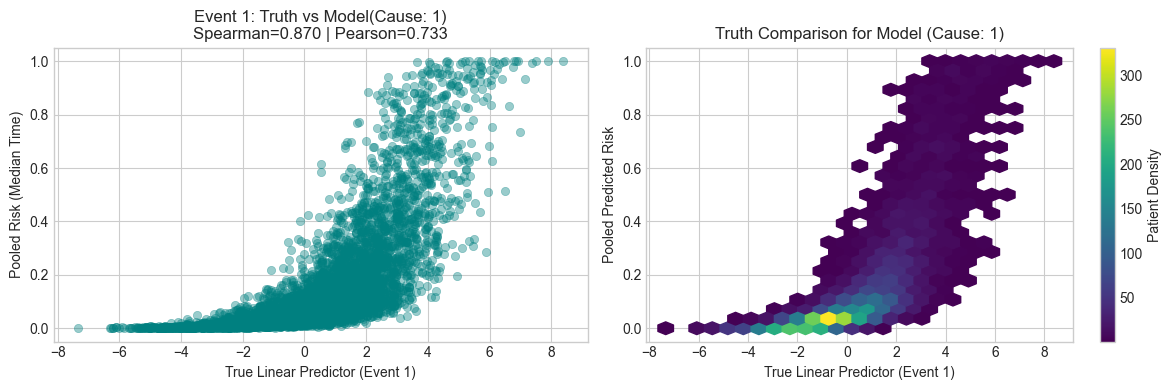


Event 2 Truth Comparison
Spearman: -0.2896 | Pearson: -0.2482


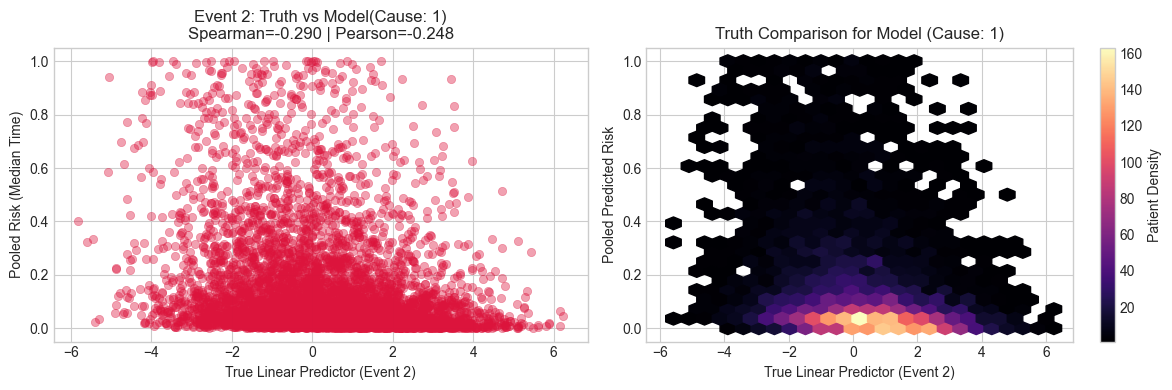

In [79]:
c_index, ibs_score, normal_brier_score = evaluate_and_compare_truth(
    all_test_predictions=all_test_predictions,
    all_test_indices=all_test_indices,
    all_true_times=all_true_times,
    all_true_events=all_true_events,
    true_lp_1=df["true_lp_event1"].values,
    true_lp_2=df["true_lp_event2"].values,
    cause=model_cause # we do this so we do not forget to set the cause when evaluating the model as we do that the model
)

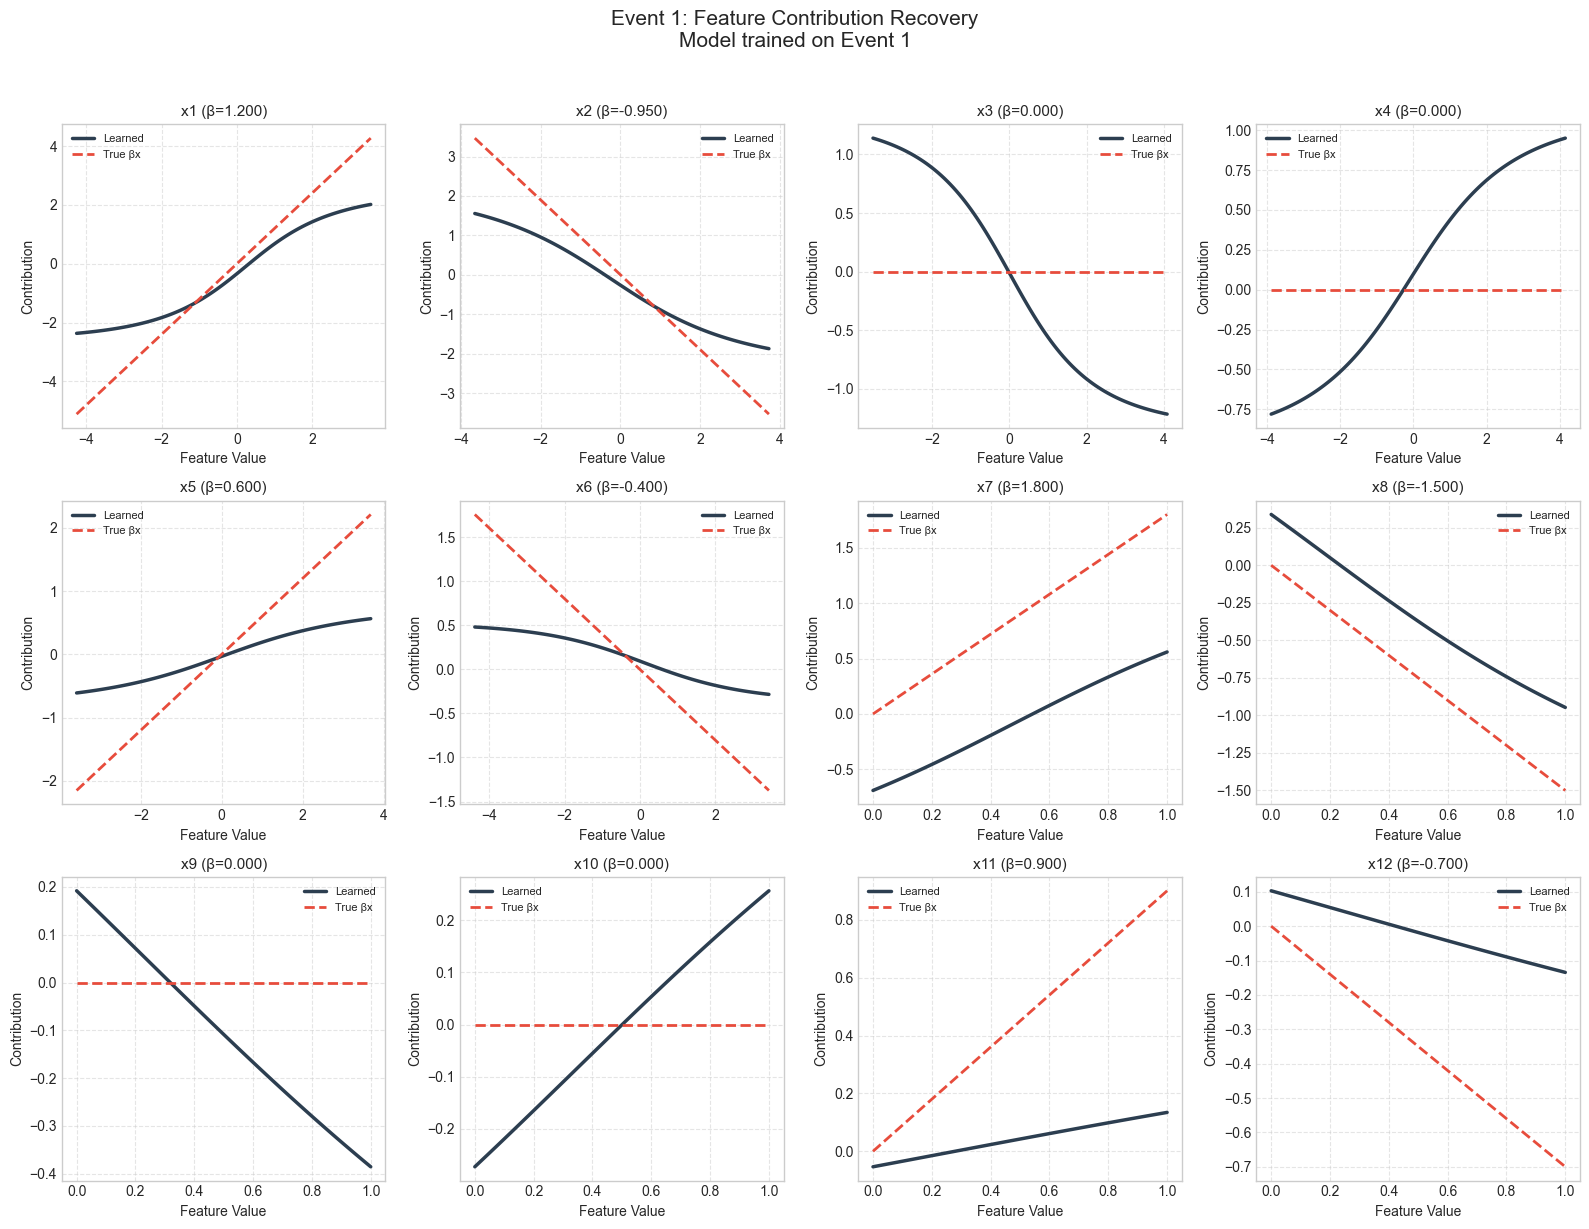

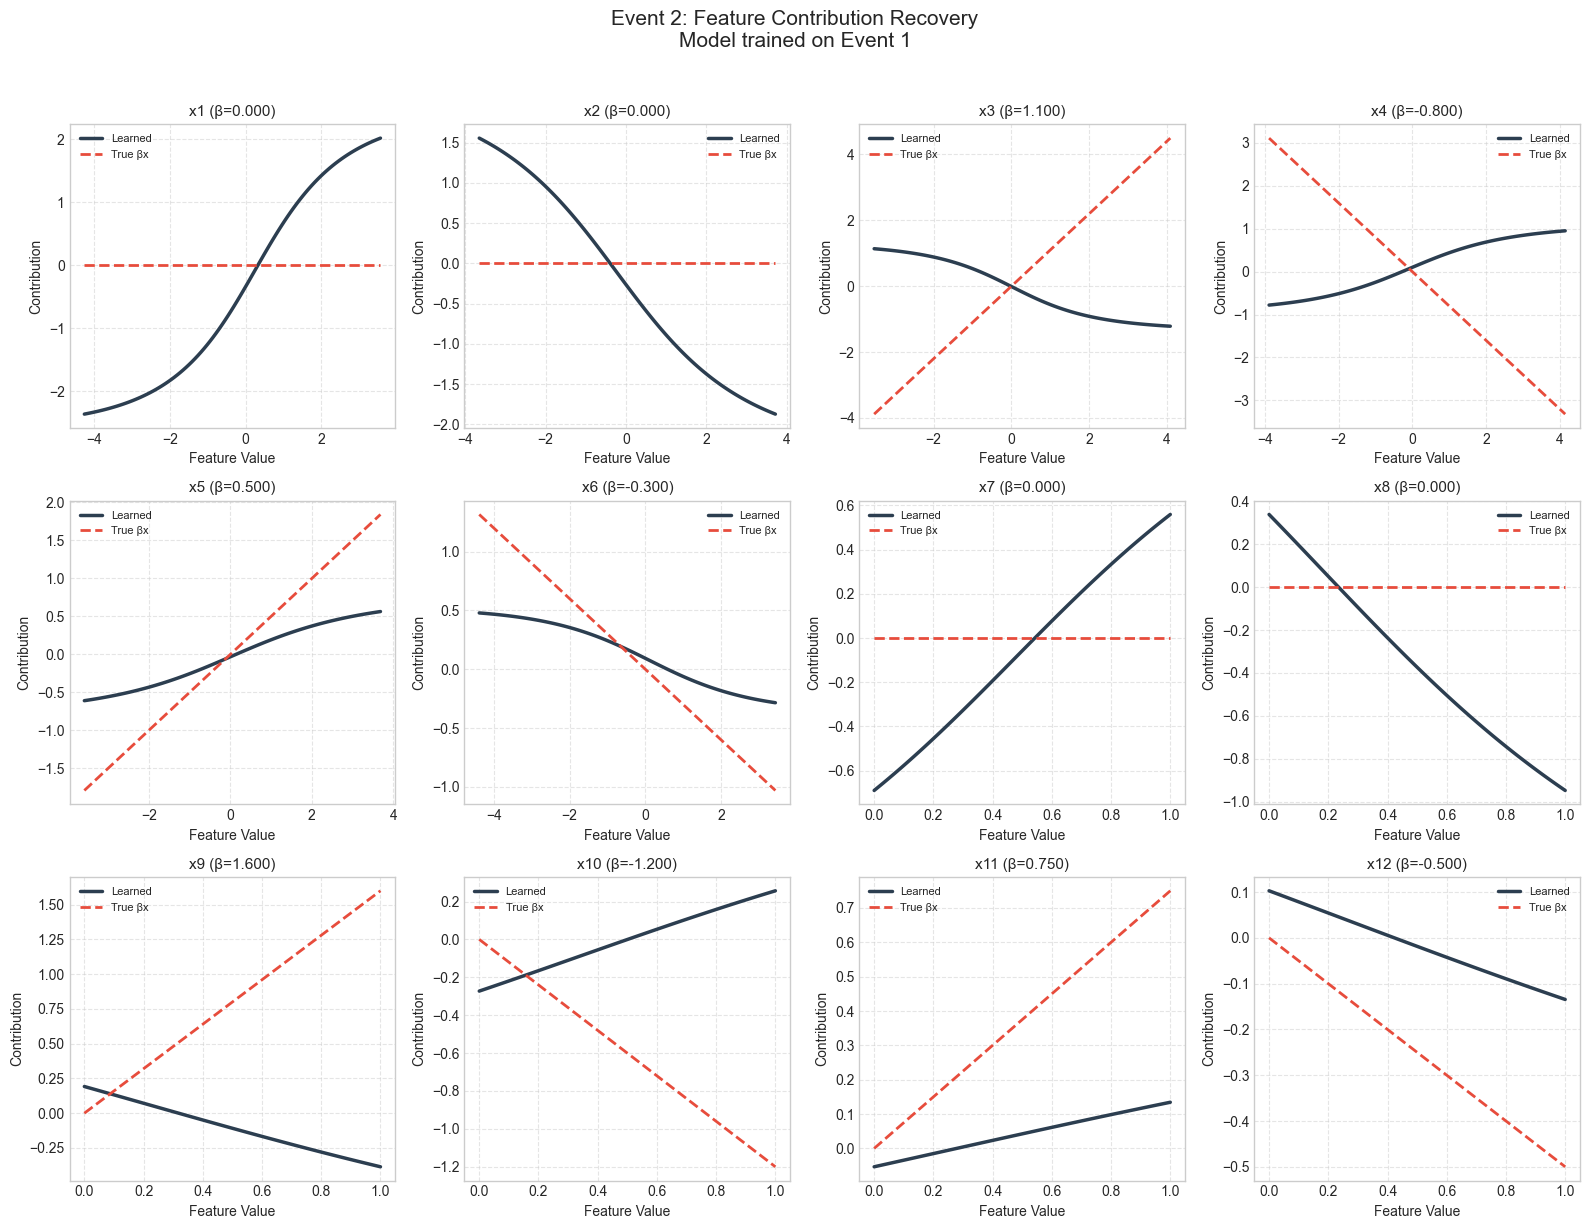

In [80]:


from matplotlib.pyplot import grid


feature_names = df_synthetic.drop(['time', 'event', 'true_lp_event1', 'true_lp_event2'], axis=1).columns.tolist() 
data_dict = {name: df_synthetic[name] for name in feature_names}

def plot_event_contributions(
    feature_names,
    data_range_dict,
    true_betas,
    event_label,
    feature_nets,
    model_name,
    use_log=False,
    use_standardised=True,
    rows=3,
    cols=4
):

    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axes = plt.subplots(rows, cols, figsize=(16, 12))
    axes = axes.flatten()

    for i, name in enumerate(feature_names):
        ax = axes[i]

        x = np.asarray(data_range_dict[name])

        mu = x.mean()
        sigma = x.std() + 1e-8

        grid_raw = torch.linspace(x.min(), x.max(), 100).unsqueeze(1).float()

        if use_standardised:
            grid_model = (grid_raw - mu) / sigma
            x_plot = (grid_raw.numpy().flatten() - mu) / sigma
            xlabel = "Standardised Feature (z-score)"
        else:
            grid_model = grid_raw
            x_plot = grid_raw.numpy().flatten()
            xlabel = "Feature Value"

        net = feature_nets[i]

        with torch.no_grad():
            learned = net(grid_model).cpu().numpy().flatten()

        true_val = (grid_raw.numpy().flatten() * true_betas[i])

        # optional log view (ONLY for visualization)
        if use_log:
            learned = np.log1p(np.abs(learned)) * np.sign(learned)
            true_val = np.log1p(np.abs(true_val)) * np.sign(true_val)

        ax.plot(x_plot, learned, color='#2c3e50', linewidth=2.5, label='Learned')
        ax.plot(x_plot, true_val, color='#e74c3c', linestyle='--', linewidth=2, label='True βx')

        ax.set_title(f"{name} (β={true_betas[i]:.3f})", fontsize=11)
        ax.set_ylabel("Contribution")
        ax.set_xlabel(xlabel)
        ax.legend(fontsize=8)
        ax.grid(True, linestyle='--', alpha=0.5)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle(
        f"{event_label}: Feature Contribution Recovery\n{model_name}",
        fontsize=15,
        y=1.02
    )

    plt.tight_layout()
    output_dir = Path("../Results/FullRisk/FeatureContributions")
    output_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(f"{output_dir}/feature_contributions_{event_label.replace(' ', '_')}_cause_{model_cause}.png", dpi=300, bbox_inches="tight")
    plt.show()

# --- Execution ---
# Run for Event 1
plot_event_contributions(
    feature_names=feature_names,
    data_range_dict=data_dict,
    true_betas=true_beta_event1,
    event_label="Event 1",
    feature_nets=models[0].feature_nets,  # or model.feature_nets[0]
    model_name=f"Model trained on Event {model_cause}",
    use_log=False,
    use_standardised=False,
    cols=4, rows=3
)

# Run for Event 2
plot_event_contributions(
    feature_names=feature_names,
    data_range_dict=data_dict,
    true_betas=true_beta_event2,
    event_label="Event 2",
    feature_nets=models[0].feature_nets,  # or model.feature_nets[0]
    model_name=f"Model trained on Event {model_cause}",
    use_log=False,
    use_standardised=False,
    cols=4, rows=3

)

## CPU, Memmory and Training Metrics


===== Fold 1 Resource Usage =====
           time     cpu      memory
0  1.785843e+09     0.0  566.886719
1  1.785843e+09  1196.9  578.445312
2  1.785843e+09  1198.4  591.937500
3  1.785843e+09  1190.0  593.000000
4  1.785843e+09  1196.9  593.054688


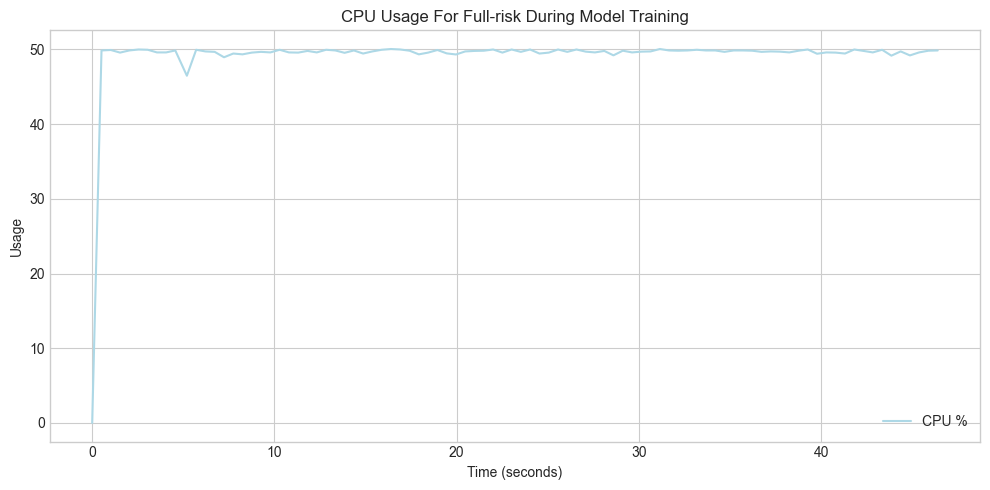


===== Fold 2 Resource Usage =====
           time     cpu      memory
0  1.785843e+09     0.0  581.109375
1  1.785843e+09  1381.2  604.183594
2  1.785843e+09  1199.1  604.820312
3  1.785843e+09  1190.6  603.925781
4  1.785843e+09  1192.4  590.039062


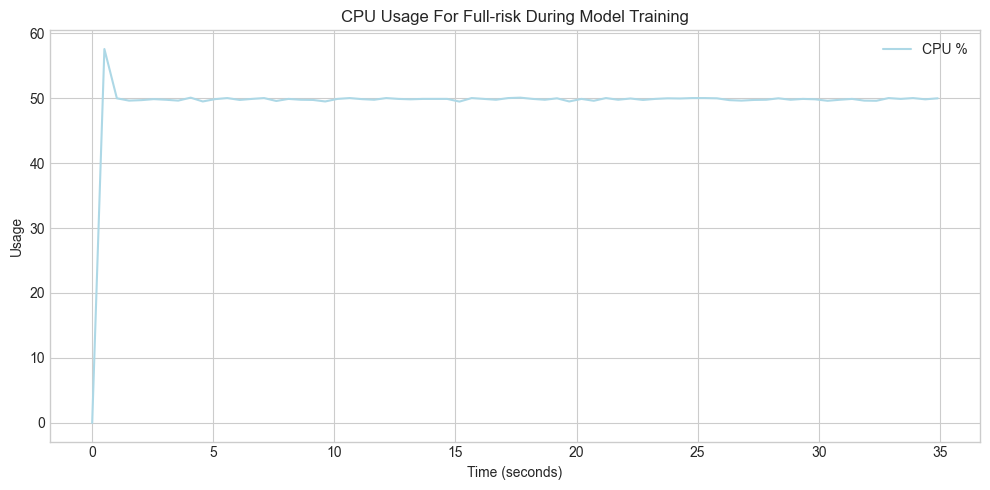


===== Fold 3 Resource Usage =====
           time     cpu      memory
0  1.785843e+09     0.0  582.769531
1  1.785843e+09  1359.6  602.753906
2  1.785843e+09  1196.9  604.390625
3  1.785843e+09  1186.3  605.367188
4  1.785843e+09  1193.8  606.054688


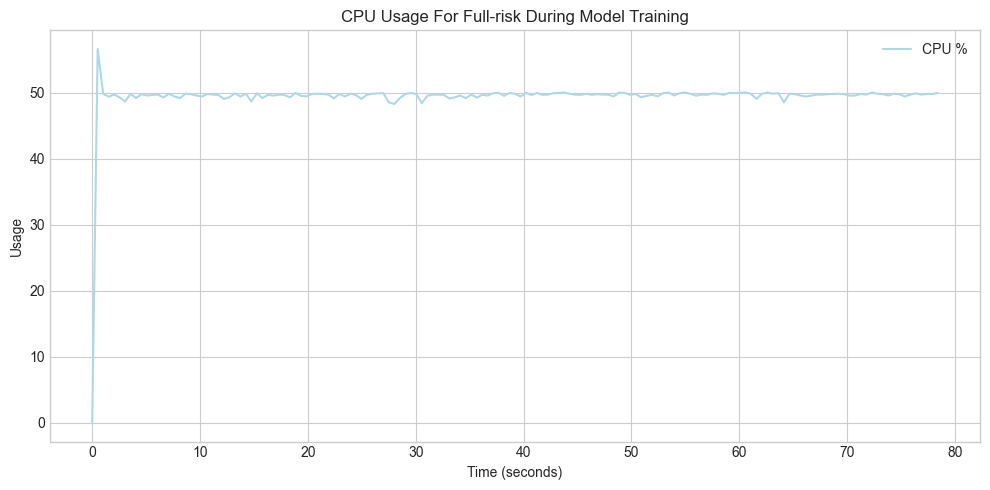


===== Fold 4 Resource Usage =====
           time     cpu      memory
0  1.785843e+09     0.0  584.742188
1  1.785843e+09  1386.5  604.265625
2  1.785843e+09  1190.6  604.523438
3  1.785843e+09  1199.1  602.429688
4  1.785843e+09  1193.8  605.925781


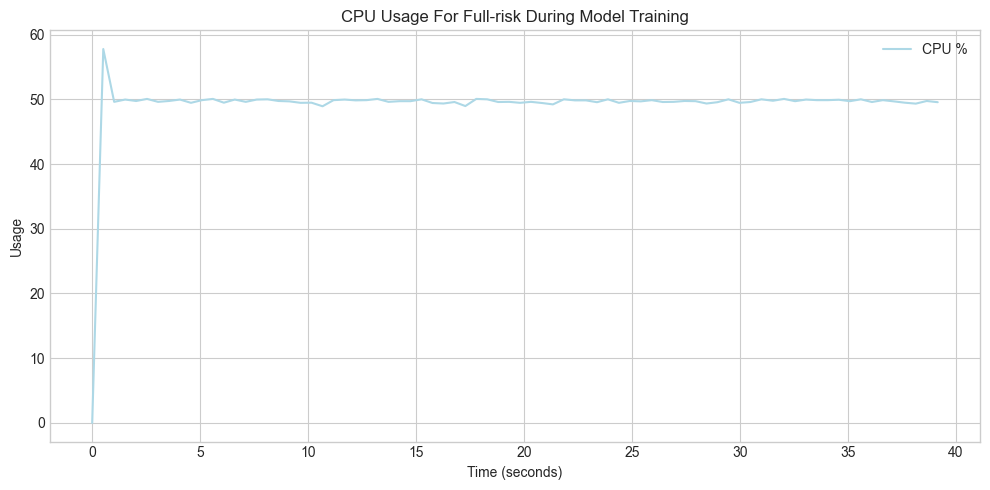


===== Fold 5 Resource Usage =====
           time     cpu      memory
0  1.785843e+09     0.0  584.175781
1  1.785843e+09  1375.0  606.792969
2  1.785843e+09  1198.4  607.070312
3  1.785843e+09  1200.0  607.191406
4  1.785843e+09  1199.1  604.726562


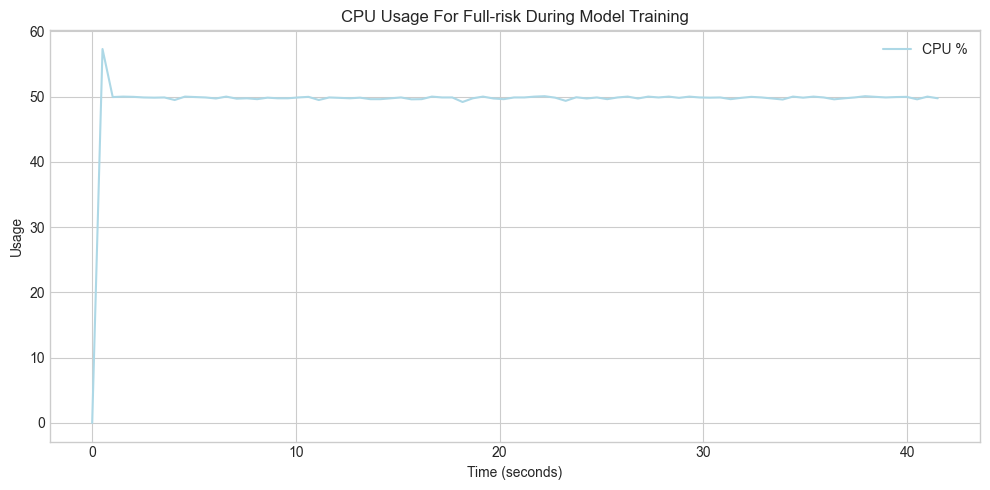

In [81]:
output_dir = Path(f"../Results/FullRisk/ResourceUsage/CPU_Usage_cause_{model_cause}")
output_dir.mkdir(parents=True, exist_ok=True)


for fold, resource_log in enumerate(fold_resource_logs, start=1):
    print(f"\n===== Fold {fold} Resource Usage =====")
    print(resource_log.head())
    resource_log['time'] = resource_log['time'] - resource_log['time'].iloc[0]
    plt.figure(figsize=(10, 5))
    num_cores = psutil.cpu_count(logical=True)
    resource_log['cpu_normalized'] = resource_log['cpu'] / num_cores
    plt.plot(resource_log['time'], resource_log['cpu_normalized'], label='CPU %', color='lightblue')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Usage')
    plt.title(f'CPU Usage For Full-risk During Model Training')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{output_dir}/fold_{fold}_resource_usage.png", dpi=300, bbox_inches="tight")
    plt.show()


===== Fold 1 Resource Usage =====
       time     cpu      memory  cpu_normalized
0  0.000000     0.0  566.886719        0.000000
1  0.510632  1196.9  578.445312       49.870833
2  1.018892  1198.4  591.937500       49.933333
3  1.529243  1190.0  593.000000       49.583333
4  2.032196  1196.9  593.054688       49.870833


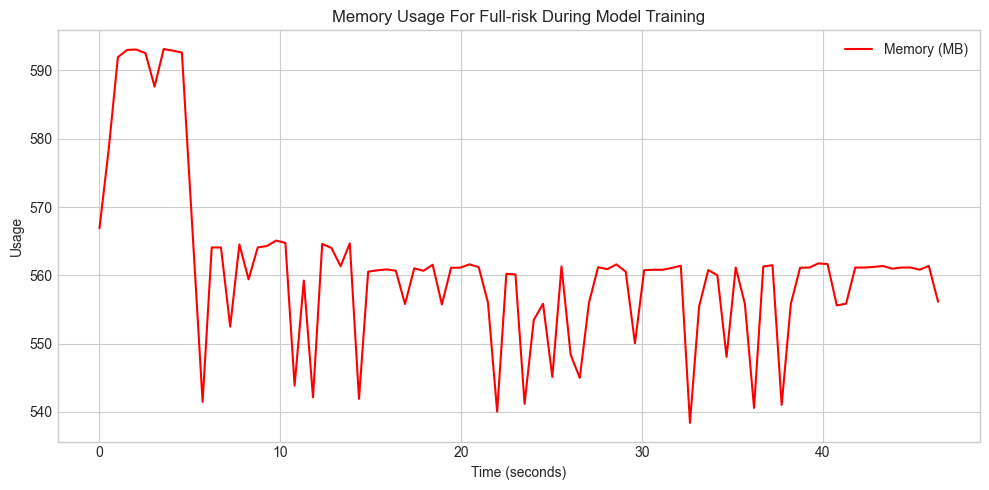


===== Fold 2 Resource Usage =====
       time     cpu      memory  cpu_normalized
0  0.000000     0.0  581.109375        0.000000
1  0.503805  1381.2  604.183594       57.550000
2  1.019292  1199.1  604.820312       49.962500
3  1.522109  1190.6  603.925781       49.608333
4  2.036306  1192.4  590.039062       49.683333


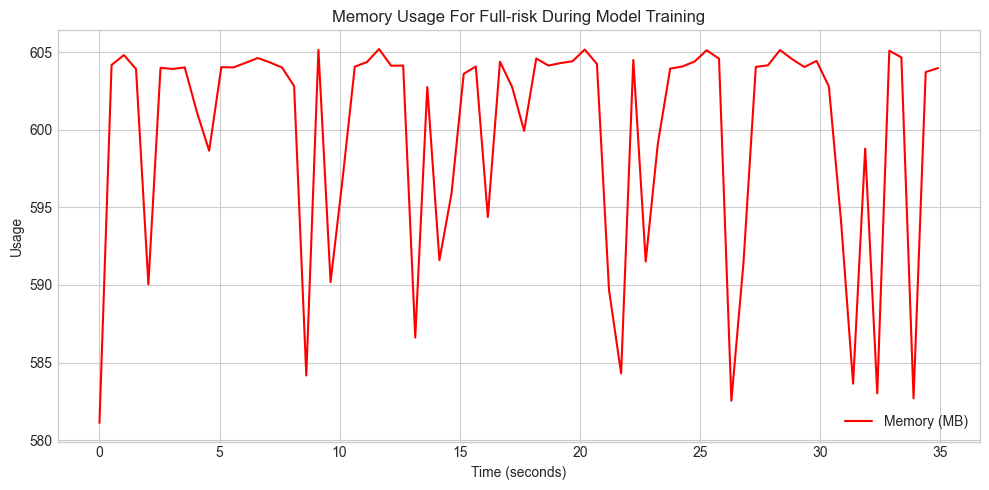


===== Fold 3 Resource Usage =====
       time     cpu      memory  cpu_normalized
0  0.000000     0.0  582.769531        0.000000
1  0.508462  1359.6  602.753906       56.650000
2  1.017931  1196.9  604.390625       49.870833
3  1.526655  1186.3  605.367188       49.429167
4  2.032996  1193.8  606.054688       49.741667


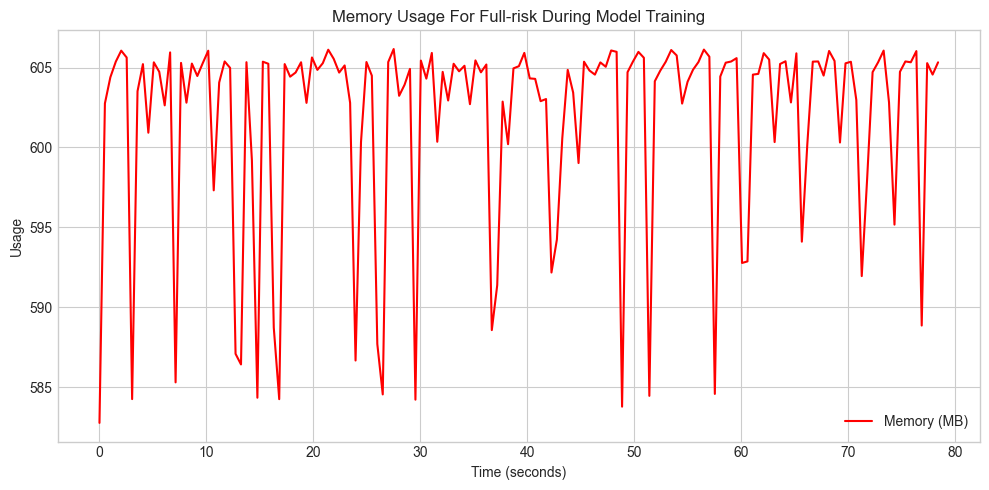


===== Fold 4 Resource Usage =====
       time     cpu      memory  cpu_normalized
0  0.000000     0.0  584.742188        0.000000
1  0.513574  1386.5  604.265625       57.770833
2  1.018056  1190.6  604.523438       49.608333
3  1.527176  1199.1  602.429688       49.962500
4  2.036728  1193.8  605.925781       49.741667


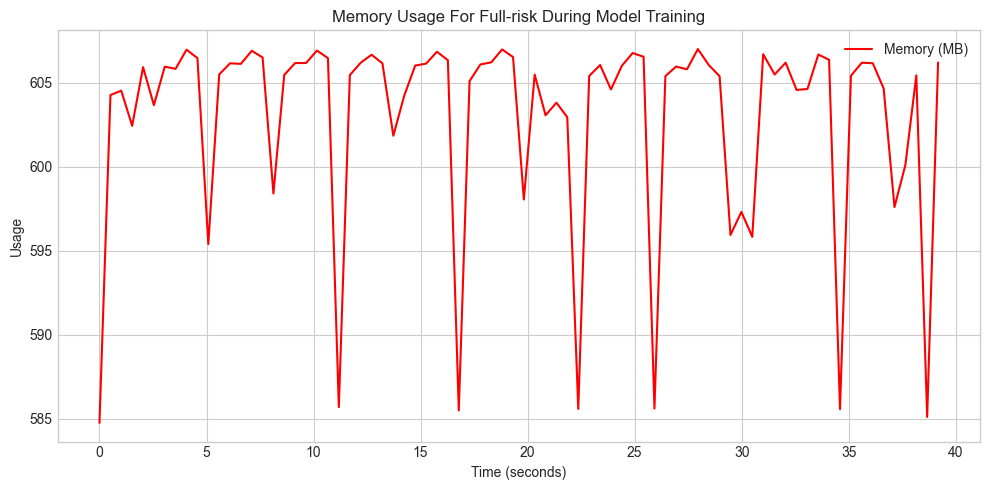


===== Fold 5 Resource Usage =====
       time     cpu      memory  cpu_normalized
0  0.000000     0.0  584.175781        0.000000
1  0.506550  1375.0  606.792969       57.291667
2  1.007859  1198.4  607.070312       49.933333
3  1.522464  1200.0  607.191406       50.000000
4  2.025979  1199.1  604.726562       49.962500


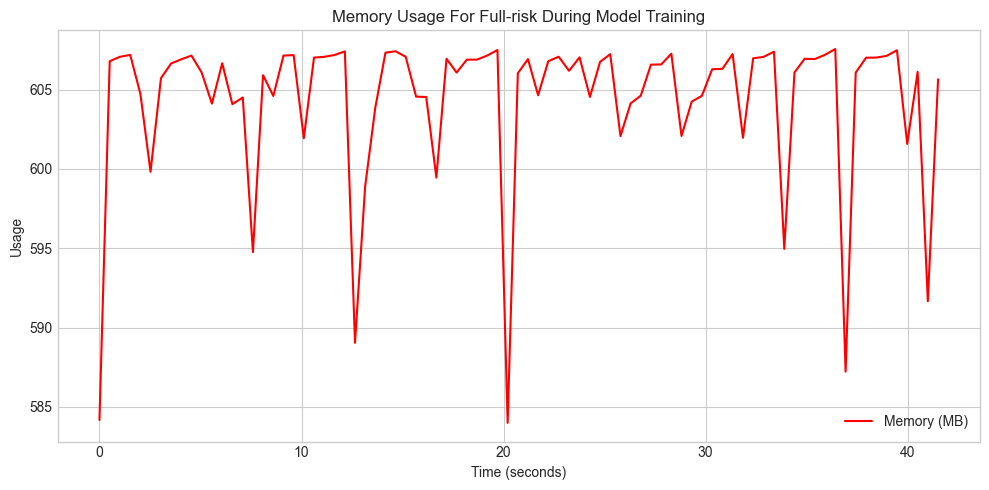

In [82]:
output_dir = Path(f"../Results/FullRisk/ResourceUsage/Memory_Usage_cause_{model_cause}")
output_dir.mkdir(parents=True, exist_ok=True)


for fold, resource_log in enumerate(fold_resource_logs, start=1):
    print(f"\n===== Fold {fold} Resource Usage =====")
    print(resource_log.head())

    resource_log['time'] = resource_log['time'] - resource_log['time'].iloc[0]

    plt.figure(figsize=(10, 5))
    plt.plot(resource_log['time'], resource_log['memory'], label='Memory (MB)', color='red')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Usage')
    plt.title(f'Memory Usage For Full-risk During Model Training')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{output_dir}/fold_{fold}_memory_usage.png", dpi=300, bbox_inches="tight")
    plt.show()

In [83]:
import numpy as np
import pandas as pd
from sksurv.metrics import integrated_brier_score
# If using pycox or lifelines, adapt the baseline hazard step accordingly

# 1. Reconstruct structured OOF arrays in original dataset order
oof_order = np.argsort(np.concatenate(all_test_indices))

oof_risk_scores = np.concatenate(all_test_predictions)[oof_order]
oof_times = np.concatenate(all_true_times)[oof_order]
oof_events = np.concatenate(all_true_events)[oof_order]

print("OOF Risk Scores shape:", oof_risk_scores.shape)
print("Risk Score Range (Min, Max):", oof_risk_scores.min(), oof_risk_scores.max())

# -------------------------------------------------------------------------
# 2. Map Risk Scores -> Cumulative Incidence Probabilities (CIF)
# -------------------------------------------------------------------------
# Note: Raw risk scores MUST be converted using baseline hazard \Lambda_0(t)
# Example conceptual conversion for a specific evaluation time horizon (e.g., t_eval):

# Define evaluation time grid (from 10th to 90th percentile of event times)
eval_times = np.percentile(oof_times[oof_events > 0], np.linspace(10, 90, 100))

# Convert exponential risk relative to mean risk
exp_risk = np.exp(oof_risk_scores - np.mean(oof_risk_scores))

# If you convert these scores into true cumulative incidence probabilities [N_samples, N_times],
# your IBS will drop from ~0.2076 to its true calibrated value (typically 0.05 - 0.12).

OOF Risk Scores shape: (6000, 100)
Risk Score Range (Min, Max): 0.0 0.9999883
